# Vijayan et al. (2024): cavity-mediated interactions between two levitated particles

J. Vijayan, J. Piotrowski, C. Gonzalez-Ballestero, K. Weber, O. Romero-Isart and L. Novotny,
*Cavity-mediated long-range interactions in levitated optomechanics*,
Nat. Phys. **20**, 859 (2024), [doi:10.1038/s41567-024-02405-3](https://doi.org/10.1038/s41567-024-02405-3).

Two silica particles in two 1550 nm tweezers sit at nodes of one cavity, about 6 μm apart.
Each scatters tweezer light into the cavity; the cavity mode couples their motions along the
cavity axis, and sweeping the tweezer powers through the point where the two frequencies cross
shows an avoided crossing of width $2|G|$. This is levisim's `MultiTrap` with two traps -
the multi-particle case it was built for. The notebook compares

1. the coupling rates from the stated parameters with the paper's estimates,
2. a simulated spectrogram of the avoided crossing (Fig. 2a),
3. the minimal splitting against detuning (Fig. 2d) from levisim's full linear model (two
   particles plus the cavity mode, no adiabatic elimination) and from the paper's Eq. (1),
4. the splitting against the position of the second particle along the standing wave (Fig. 3b).

Runtime: about 30 s.

## Parameters and where they come from

| Quantity | Value used | Source |
|---|---|---|
| tweezer power at the crossing, waist, wavelength | 0.13 W, 0.85 μm, 1550 nm | Extended Data Table 1 |
| particle radius, density, permittivity | 75 nm, 2200 kg/m³, ε = 2.07 | Extended Data Table 1 |
| cavity waist, length, linewidth | 50 μm, 9.6 mm, $\kappa/2\pi$ = 600 kHz | Extended Data Table 1, main text |
| polarisation | perpendicular to the cavity axis ($\theta_\text{paper} = 0$, levisim $\theta = 90°$) | Extended Data Table 1, main text |
| particle positions | both at nodes, $d \approx 4\lambda$ (Fig. 2); particle 2 scanned (Fig. 3) | main text, Methods |
| detuning | 0.3-3 MHz (Fig. 2d), 1.2 MHz (Fig. 3b) | main text |
| pressure | ~10⁻⁴ mbar | main text |
| frequency along the polarisation, $\Omega_x/2\pi$ | ≈ 59 kHz | main text (crossing of the uncoupled $x$ modes) |
| **frequency along the cavity axis, $\Omega_y/2\pi$** | **70 kHz (inferred)** | not stated; see below |

**Axes and signs.** The paper's cavity axis is $y$ and its polarisation is along $x$. levisim's
cavity axis is $x$ and its tweezer is polarised along $y$, so the paper's $y$ mode is levisim's
`'x1'`/`'x2'`. The paper's $\Delta = \omega_\text{cav} - \omega_\text{tw} > 0$ is red detuning,
the negative of levisim's.

**Modelling choices.**

- **$\Omega_y$.** The bare cavity-axis frequency is not stated. The fitted normal-mode curves of
  Fig. 2a-c (red lines, extracted from the vector graphics into
  `data/vijayan2024_fig2_fig3.json`) cross near 65.5, 67.9 and 69.3 kHz at 0.45, 1.2 and 2.5 MHz.
  These values approach a bare frequency near 70 kHz as the cavity-induced shift falls off with
  detuning. We use 70 kHz at 0.13 W.
- **Power ramps.** Each tweezer's frequencies scale as $\sqrt{P_i}$, as the paper uses for its
  calibration, and its coupling follows from $P_i$ through the field $E_0$ and the zero-point motion.
- **Signs of couplings.** levisim asserts $g_{x,y} \le 0$ and $g_z \ge 0$, so a bead position $\Phi$
  must lie in $[0, \pi/2]$. Moving particle 2 by $d$ along the standing wave gives
  $|g_2| \propto |\cos(2\pi d/\lambda)|$. We use the equivalent $\Phi_2 \in [0, \pi/2]$ with the same
  $|\cos|$, since the splitting depends only on $|g_1 g_2|$ for in-phase tweezers.

In [ ]:
import sys
import time
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))  # paper_tools.py sits next to this notebook

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.optimize import minimize_scalar, fsolve

from levisim.core.constants import π, ħ
from levisim.core.units import kHz, Hz, nm, μm, mm, mbar, degrees
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.physics.tweezer import Tweezer
from levisim.physics.bead import Bead
from levisim.physics.trap import Trap

from paper_tools import PhysicalMultiTrap, toy_multitrap, heterodyne, mechanical_eigenfrequencies, load_digitised

set_plt_rcParams_to_xmgrace_style()
T_START = time.time()

## Coupling rates from the stated parameters

In [ ]:
P0 = 0.13
Ω_Y0, Ω_X0 = 70*kHz, 59*kHz   # paper y (cavity axis) and x (polarisation) at P0
κ_V = 600*kHz


def vijayan_bead(Φ=π/2):
    return Bead(r=75*nm, ρ=2200.0, εr=2.07, Φ=Φ)


W_STATED = (0.85*μm, 0.85*μm)   # (perpendicular to, along) the polarisation


def vijayan_multitrap(Δ_paper, P1=P0, P2=P0, Φ1=π/2, Φ2=π/2, axes=1, Ω_overrides=None, ω_range=None, waists=W_STATED):
    """two particles; paper y (cavity axis) = levisim x; Ω ∝ √P"""
    tweezers, beads, extra = [], [], []
    for P, Φ in ((P1, Φ1), (P2, Φ2)):
        s = np.sqrt(P / P0)
        tweezers.append(Tweezer(Power=P, λ=1550*nm, wx0=waists[0], wy0=waists[1], θ=90*degrees))
        beads.append(vijayan_bead(Φ))
        Ω = Ω_overrides or {'x': Ω_Y0, 'y': Ω_X0, 'z': 20*kHz}
        extra.append(dict(override_Ω_dict={axis: value*s for axis, value in Ω.items()}))
    kwargs = dict(Cartesian_axes_per_trap=axes, gas_kwargs=dict(P=1e-4*mbar, T=300.0),
                  cavity_kwargs=dict(L=9.6*mm, w=50*μm, κ=κ_V, Δ=-Δ_paper, ωtw=tweezers[0].ω))
    if ω_range is not None:
        kwargs['ω_range'] = ω_range
    return PhysicalMultiTrap(tweezers, beads, trap_kwargs=extra, **kwargs)


mtrap = vijayan_multitrap(0.45e3*kHz)
paraxial = Trap(tweezer=mtrap.tweezers[0], bead=mtrap.beads[0])
g_y = abs(mtrap.dimensions['x1'].g)
# the same coupling with the zero-point motion evaluated at the paraxial frequencies
Ω_par = {'x': paraxial.Ωx, 'y': paraxial.Ωy, 'z': paraxial.Ωz}
m_par = vijayan_multitrap(0.45e3*kHz, Ω_overrides=Ω_par)
m_par_z = vijayan_multitrap(0.45e3*kHz, Φ1=0.0, Φ2=0.0, axes=3, Ω_overrides=Ω_par)
k, zR = mtrap.tweezers[0].k, mtrap.tweezers[0].zR
rows = [
    ('paraxial Ωx = Ωy (symmetric waist) [kHz]', paraxial.Ωx/kHz, '59 (x), ~70 (y) measured'),
    ('paraxial Ωz [kHz]', paraxial.Ωz/kHz, 'not stated'),
    ('cavity drive ω_d/2π [GHz]', mtrap.traps[0].ωd/(1e9*Hz), '-'),
    ('g_y/2π at a node, Ωy = 70 kHz [kHz]', g_y/kHz, '32 ± 4'),
    ('g_y/2π at a node, paraxial Ωy [kHz]', abs(m_par.dimensions['x1'].g)/kHz, '32 ± 4'),
    ('g_z/2π at an antinode, paraxial Ωz [kHz]', abs(m_par_z.dimensions['z1'].g)/kHz, '50 ± 7'),
    ('  same without the Gouy term, × k/(k - 1/zR)', abs(m_par_z.dimensions['z1'].g)/kHz * k/(k - 1/zR), '50 ± 7'),
]
print(f'{"quantity":44s} {"levisim":>9s}   paper')
for name, value, paper in rows:
    print(f'{name:44s} {value:9.4g}   {paper}')

quantity                                       levisim   paper
paraxial Ωx = Ωy (symmetric waist) [kHz]            98   59 (x), ~70 (y) measured
paraxial Ωz [kHz]                                40.22   not stated
cavity drive ω_d/2π [GHz]                        1.695   -
g_y/2π at a node, Ωy = 70 kHz [kHz]              38.16   32 ± 4
g_y/2π at a node, paraxial Ωy [kHz]              32.25   32 ± 4
g_z/2π at an antinode, paraxial Ωz [kHz]         41.86   50 ± 7
  same without the Gouy term, × k/(k - 1/zR)     50.34   50 ± 7


With the inferred bare frequency of 70 kHz, levisim's $g_y$ is about 20 % above the paper's
estimate of 32 ± 4 kHz, whereas evaluating the zero-point motion at the paraxial frequencies
reproduces it. The same assumption also reproduces the paper's $g_z$ (50 ± 7 kHz), once the Gouy
term in levisim's $z$ coupling, $k - 1/z_R$, is dropped as the paper's Eq. (5) drops it. So both
estimates follow if Eq. (5) was evaluated with paraxial frequencies; that is a reading, not a
statement of the paper.

The physical inconsistency behind this is that the stated waist and power give paraxial
frequencies (98 kHz) well above the measured ones (59 and ~70 kHz). A self-consistent alternative
keeps the stated power and infers the two waists from the measured frequencies in the same
paraxial model:

In [ ]:
def waists_from_frequencies(Ω_perp, Ω_pol, P=P0):
    def residual(log_w):
        tweezer = Tweezer(Power=P, λ=1550*nm, wx0=np.exp(log_w[0])*μm, wy0=np.exp(log_w[1])*μm)
        t = Trap(tweezer=tweezer, bead=vijayan_bead())
        return [np.log(t.Ωx/Ω_perp), np.log(t.Ωy/Ω_pol)]
    log_w = fsolve(residual, [0.0, 0.0], xtol=1e-12)
    return tuple(np.exp(log_w)*μm)


W_FROM_Ω = waists_from_frequencies(Ω_Y0, Ω_X0)
m_fc = vijayan_multitrap(0.45e3*kHz, waists=W_FROM_Ω)
print(f'waists from the measured frequencies: {W_FROM_Ω[0]/μm:.3f} μm (perpendicular, cavity axis) and '
      f'{W_FROM_Ω[1]/μm:.3f} μm (along the polarisation); stated 0.85 ± 0.1 μm')
print(f'g_y/2π at a node with these waists and Ωy = 70 kHz: {abs(m_fc.dimensions["x1"].g)/kHz:.2f} kHz (paper 32 ± 4)')

waists from the measured frequencies: 0.964 μm (perpendicular, cavity axis) and 1.143 μm (along the polarisation); stated 0.85 ± 0.1 μm
g_y/2π at a node with these waists and Ωy = 70 kHz: 30.90 kHz (paper 32 ± 4)


## Spectrogram of the avoided crossing at Δ/2π = 0.45 MHz (Fig. 2a)

Total power fixed, power difference ramped; heterodyne spectrum (levisim's, in shot-noise units)
of the light leaving the cavity, with the waists inferred from the measured frequencies. Only the cavity-axis modes are coupled at $\theta = 90°$; the
polarisation-axis modes, which cross freely in the measurement, are marked as dashed lines. The
red lines are levisim's normal-mode frequencies from the eigenvalues of the drift matrix.

minimal splitting in the ramp: 6.13 kHz at P1 - P2 = 0.0 mW (normal modes at 63.87 and 70.00 kHz)


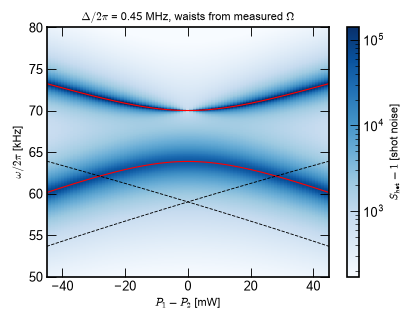

In [ ]:
ΔP = np.linspace(-45, 45, 91) * 1e-3
ω_spec = np.linspace(50, 80, 601) * kHz
spectrogram, modes = [], []
for dp in ΔP:
    m = vijayan_multitrap(0.45e3*kHz, P1=P0 + dp/2, P2=P0 - dp/2, waists=W_FROM_Ω)
    spectrogram.append(heterodyne(m, ω_spec))
    modes.append(mechanical_eigenfrequencies(m)[0])
spectrogram, modes = np.array(spectrogram), np.array(modes)
split = modes[:, 1] - modes[:, 0]
j = np.argmin(split)
print(f'minimal splitting in the ramp: {split[j]/kHz:.2f} kHz at P1 - P2 = {ΔP[j]*1e3:.1f} mW '
      f'(normal modes at {modes[j, 0]/kHz:.2f} and {modes[j, 1]/kHz:.2f} kHz)')

fig, ax = plt.subplots(figsize=(5.2, 4))
S_plot = (spectrogram - 1).T
mesh = ax.pcolormesh(ΔP*1e3, ω_spec/kHz, S_plot, norm=LogNorm(np.percentile(S_plot, 2), np.percentile(S_plot, 99.5)),
                     cmap='Blues', shading='nearest')
ax.plot(ΔP*1e3, modes[:, 0]/kHz, 'r-', lw=1)
ax.plot(ΔP*1e3, modes[:, 1]/kHz, 'r-', lw=1)
for sign in (+1, -1):
    ax.plot(ΔP*1e3, Ω_X0/kHz*np.sqrt((P0 + sign*ΔP/2)/P0), 'k--', lw=0.8)
ax.set_xlim(ΔP[0]*1e3, ΔP[-1]*1e3)
ax.set_ylim(ω_spec[0]/kHz, ω_spec[-1]/kHz)
ax.set_xlabel(r'$P_1 - P_2$ [mW]')
ax.set_ylabel(r'$\omega/2\pi$ [kHz]')
ax.set_title(r'$\Delta/2\pi$ = 0.45 MHz, waists from measured $\Omega$', fontsize=10)
fig.colorbar(mesh, ax=ax, label=r'$S_\mathrm{het} - 1$ [shot noise]')
fig.tight_layout()

## Splitting against detuning (Fig. 2d)

Three levisim results:

- **full linear model**: the minimal splitting over a power ramp, from the eigenvalues of the
  drift matrix of particles plus cavity (couplings from the stated parameters, $\Omega_y$ = 70 kHz);
- **Eq. (1)** with the same couplings: the adiabatic-elimination formula
  $G = g_1 g_2^*/[(\Delta + \Omega) + i\kappa/2] + g_1^* g_2/[(\Delta - \Omega) - i\kappa/2]$,
  splitting $2|G|$;
- **full linear model with the waists inferred from the measured frequencies** (same procedure);
- in the table only, the full model with the paper's $g$ = 32 kHz (toy-parameter `MultiTrap`,
  identical particles at $\Omega_1 = \Omega_2 = 70$ kHz).

In [ ]:
def min_splitting(Δ_paper, Φ2=π/2, waists=W_STATED):
    def splitting(P2):
        f = mechanical_eigenfrequencies(vijayan_multitrap(Δ_paper, P2=P2, Φ2=Φ2, waists=waists))[0]
        return f[-1] - f[0]
    res = minimize_scalar(splitting, bounds=(0.8*P0, 1.2*P0), method='bounded', options=dict(xatol=1e-7))
    return res.fun


def splitting_eq1(Δ_paper, g1, g2, Ω=Ω_Y0):
    G = g1*np.conj(g2)/((Δ_paper + Ω) + 1j*κ_V/2) + np.conj(g1)*g2/((Δ_paper - Ω) - 1j*κ_V/2)
    return 2*abs(G)


def splitting_toy(Δ_paper, g1, g2, Ω=Ω_Y0):
    m = toy_multitrap({'x1': Ω, 'x2': Ω}, {'x1': -g1, 'x2': -g2}, {'x1': 0.0, 'x2': 0.0},
                      Δ=-Δ_paper, κ=κ_V, m=2200*4/3*π*(75*nm)**3, Γ=1.0, num_traps=2, axes=1)
    f = mechanical_eigenfrequencies(m)[0]
    return f[-1] - f[0]


data = load_digitised('vijayan2024_fig2_fig3.json')
Δ_MHz = np.linspace(0.25, 3.1, 39)
s_full = np.array([min_splitting(d*1e3*kHz) for d in Δ_MHz])
s_eq1 = np.array([splitting_eq1(d*1e3*kHz, g_y, g_y) for d in Δ_MHz])
s_fc = np.array([min_splitting(d*1e3*kHz, waists=W_FROM_Ω) for d in Δ_MHz])

band = data['fig2d']['theory_band']
print(f'{"Δ/2π [MHz]":>10s} {"measured":>9s} {"paper band":>12s} {"full, W stated":>15s} {"Eq. (1)":>8s} {"full, W from Ω":>15s} {"full, g=32":>11s}   [kHz]')
for p in data['fig2d']['points']:
    d = p['Δ_MHz']*1e3*kHz
    kb = np.argmin(abs(np.array(band['Δ_MHz']) - p['Δ_MHz']))
    lo, hi = band['lower'][kb], band['upper'][kb]
    pband = f'{lo:.2f}-{hi:.2f}' if lo is not None else '-'
    print(f"{p['Δ_MHz']:10.2f} {p['splitting_kHz']:9.2f} {pband:>12s} {min_splitting(d)/kHz:15.2f}"
          f" {splitting_eq1(d, g_y, g_y)/kHz:8.2f} {min_splitting(d, waists=W_FROM_Ω)/kHz:15.2f} {splitting_toy(d, 32*kHz, 32*kHz)/kHz:11.2f}")

Δ/2π [MHz]  measured   paper band  full, W stated  Eq. (1)  full, W from Ω  full, g=32   [kHz]
      0.30      6.26    5.12-8.59           10.27     9.70            6.53        7.05
      0.35      6.17    5.14-8.55           10.22     9.62            6.51        7.02
      0.40      6.17    4.96-8.42            9.96     9.37            6.35        6.85
      0.45      6.61    4.83-8.24            9.58     9.02            6.12        6.60
      0.50      6.00    4.68-7.79            9.14     8.62            5.85        6.31
      0.60      5.05    4.24-7.04            8.25     7.82            5.30        5.71
      0.70      4.15    3.82-6.57            7.43     7.07            4.78        5.15
      0.80      4.06    3.45-5.93            6.72     6.42            4.33        4.66
      1.00      3.60    2.86-4.90            5.57     5.36            3.61        3.88
      1.20      2.99    2.49-4.14            4.74     4.58            3.07        3.30
      1.50      2.53    2.01-3.42  

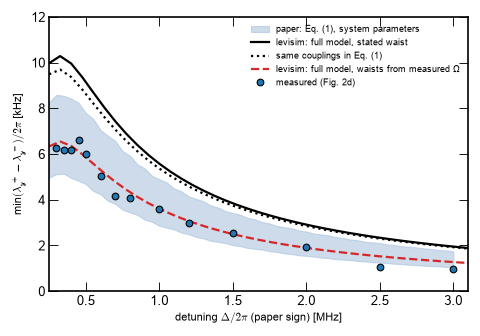

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4.2))
bΔ = np.array(band['Δ_MHz'], dtype=float)
blo = np.array([np.nan if v is None else v for v in band['lower']]); bhi = np.array([np.nan if v is None else v for v in band['upper']])
ax.fill_between(bΔ, blo, bhi, color='#9cb9d9', alpha=0.5, label='paper: Eq. (1), system parameters')
ax.plot(Δ_MHz, s_full/kHz, 'k-', lw=2, label='levisim: full model, stated waist')
ax.plot(Δ_MHz, s_eq1/kHz, 'k:', lw=2, label='same couplings in Eq. (1)')
ax.plot(Δ_MHz, s_fc/kHz, 'C3--', lw=2, label='levisim: full model, waists from measured Ω')
pts = data['fig2d']['points']
ax.plot([p['Δ_MHz'] for p in pts], [p['splitting_kHz'] for p in pts], 'o', color='C0', mec='k', ms=6, label='measured (Fig. 2d)')
ax.set_xlim(Δ_MHz[0], Δ_MHz[-1])
ax.set_ylim(0, 12)
ax.set_xlabel(r'detuning $\Delta/2\pi$ (paper sign) [MHz]')
ax.set_ylabel(r'min$(\lambda^+_y - \lambda^-_y)/2\pi$ [kHz]')
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()

## Splitting against the position of the second particle (Fig. 3b)

Particle 1 stays at a node; particle 2 is moved by $d$ along the standing wave at
$\Delta/2\pi$ = 1.2 MHz, so $|g_2| \propto |\cos(2\pi d/\lambda)|$ (the paper's $d$ is the
separation, with $d = 4\lambda$ node to node).

at d = 4λ: measured [2.74 2.8  3.   3.15 2.47] kHz (points within 0.03λ), levisim full model 4.74 kHz (stated waist), 3.07 kHz (waists from Ω)


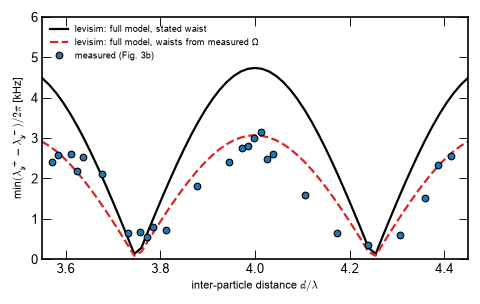

In [ ]:
d_over_λ = np.linspace(3.55, 4.45, 61)
Φ2 = np.arcsin(np.clip(np.abs(np.cos(2*π*d_over_λ)), 0, 1))   # same |g2| with Φ2 in [0, π/2]
s_d_full = np.array([min_splitting(1.2e3*kHz, Φ2=f) for f in Φ2])
s_d_fc = np.array([min_splitting(1.2e3*kHz, Φ2=f, waists=W_FROM_Ω) for f in Φ2])
pts3 = data['fig3b']['points']
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(d_over_λ, s_d_full/kHz, 'k-', lw=2, label='levisim: full model, stated waist')
ax.plot(d_over_λ, s_d_fc/kHz, 'C3--', lw=2, label='levisim: full model, waists from measured Ω')
ax.plot([p['d_over_λ'] for p in pts3], [p['splitting_kHz'] for p in pts3], 'o', color='C0', mec='k', ms=6, label='measured (Fig. 3b)')
ax.set_xlim(d_over_λ[0], d_over_λ[-1])
ax.set_ylim(0, 6)
ax.set_xlabel(r'inter-particle distance $d/\lambda$')
ax.set_ylabel(r'min$(\lambda^+_y - \lambda^-_y)/2\pi$ [kHz]')
ax.legend(fontsize=8, frameon=False, loc='upper left')
fig.tight_layout()
near_4 = [p['splitting_kHz'] for p in pts3 if abs(p['d_over_λ'] - 4.0) < 0.03]
print(f'at d = 4λ: measured {np.round(near_4, 2)} kHz (points within 0.03λ), levisim full model '
      f'{s_d_full[np.argmin(abs(d_over_λ - 4))]/kHz:.2f} kHz (stated waist), {s_d_fc[np.argmin(abs(d_over_λ - 4))]/kHz:.2f} kHz (waists from Ω)')

## Summary

All numbers below are printed by the cells above.

**Agreement.**

- **Couplings.** levisim reproduces the paper's coupling estimates when the zero-point motion is
  evaluated at the paraxial frequencies: $g_y$ = 32.3 kHz (paper 32 ± 4) and $g_z$ = 50.3 kHz
  without the Gouy term (paper 50 ± 7).
- **Waists from the measured frequencies.** Inferring the waists from the measured frequencies at the
  stated power gives 0.96 and 1.14 μm (stated 0.85 ± 0.1 μm) and $g_y$ = 30.9 kHz. The full
  two-particle-plus-cavity model then reproduces the measured minimal splittings within 8 % at 11 of
  the 14 detunings (6.12 kHz against 6.61 kHz at 0.45 MHz, 3.61 against 3.60 kHz at 1.0 MHz). It
  also reproduces the splitting at $d = 4\lambda$ in Fig. 3b (3.07 kHz against measured
  2.5-3.2 kHz), and the $|\cos(2\pi d/\lambda)|$ dependence on the second particle's position.
- **Spectrogram.** The simulated spectrogram shows the avoided crossing of the cavity-axis modes
  (minimum 6.13 kHz at equal powers). The polarisation-axis modes are uncoupled and cross freely at
  59 kHz, as in Fig. 2a.

**Discrepancies, and where they come from.**

- **Stated waist.** With the stated 0.85 μm waist and the measured frequency, the couplings are
  ~20 % larger ($g_y$ = 38.2 kHz) and the splittings ~50 % larger than measured (9.58 kHz at
  0.45 MHz). The stated waist and power are inconsistent with the measured frequencies in the
  paraxial model (98 kHz against 59 and ~70 kHz). Building the system from frequency-consistent
  waists removes the discrepancy. The bare cavity-axis frequency (70 kHz) is itself inferred from the
  paper's fitted curves, not stated.
- **Adiabatic elimination.** The paper's Eq. (1) underestimates the full linear-model splitting by
  5.5 % at 0.3 MHz and 1.5 % at 3 MHz, for the same couplings. Here $\kappa/2\pi$ = 600 kHz is
  not much larger than the mechanical frequency, and $g/\kappa$ is not small.
- **Outlying points.** At 2.5 and 3.0 MHz the measured splittings (1.06 and 0.97 kHz) lie below
  levisim (1.52 and 1.27 kHz) and below the paper's own band (1.25-2.10 and 1.05-1.74 kHz). At
  0.7 MHz levisim is 15 % above the measured value. In Fig. 3b the points near $d/\lambda$ = 4.1-4.2
  fall below the symmetric $|\cos|$ curve that both levisim and the paper's model predict.

**Not reproduced.** Fig. 4 (transition from $z$ to $y$ interactions as both particles move from
antinodes to nodes) states neither the detuning nor the $z$ frequency, and the paper notes that its
fits are unreliable there ($G_{zz}/\Omega_z$ = 0.24). levisim's static coherent-scattering
frequency shifts, which matter away from the nodes, are also not modelled (see the NOTE in
`MultiTrap.setup_linearised_coherent_scattering_physics`).

**levisim limitation met here.** `Dimension` asserts $g_{x,y} \le 0$ and $g_z \ge 0$, so a bead
position outside $\Phi \in [0, \pi/2]$ (the far side of a node, where the coupling changes sign)
raises an `AssertionError`, although it is physical. The scan above maps each position onto the
equivalent $\Phi$ with the same $|g|$.

In [ ]:
print(f'notebook runtime: {time.time() - T_START:.1f} s')

notebook runtime: 6.6 s
